# Modeling and Simulation: Problem Sheet 7, exercise 1

```text
Problem sheet 7, exercise 1(b)-(d).

Harmonic oscillator written as a system of two first-order ODEs

    x'(t) = y(t),    y'(t) = -x(t),    x(0) = 1,  y(0) = 0

solved with
    (i)   forward (explicit) Euler
    (ii)  backward (implicit) Euler
    (iii) semi-implicit Euler (Euler-Cromer)
    (iv)  2nd order Runge-Kutta (midpoint) method

Exact solution: x(t) = cos t, y(t) = -sin t, i.e. the unit circle,
and E = x^2 + y^2 = 1 for all t.
```

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ---------------- parameters ----------------
N = 50            # number of time steps (50 steps -> 51 points incl. the start)
h = 0.2           # step size for the Euler methods and the first RK2 run
h_big = 0.5       # larger step size for the second RK2 run
x0, y0 = 1.0, 0.0 # initial conditions x(0) = 1, y(0) = 0

In [4]:
# ---------------- arrays for all methods ----------------
# index n holds the approximation at t_n = n*h, so N steps need N+1 entries
x_fe = np.zeros(N + 1); y_fe = np.zeros(N + 1)   # (i)   forward Euler,  h = 0.2
x_be = np.zeros(N + 1); y_be = np.zeros(N + 1)   # (ii)  backward Euler, h = 0.2
x_si = np.zeros(N + 1); y_si = np.zeros(N + 1)   # (iii) semi-implicit,  h = 0.2
x_rk = np.zeros(N + 1); y_rk = np.zeros(N + 1)   # (iv)  RK2 midpoint,   h = 0.2
x_rk5 = np.zeros(N + 1); y_rk5 = np.zeros(N + 1) # (iv)  RK2 midpoint,   h = 0.5

# initial conditions: every method starts at the same point (1, 0)
for xa, ya in ((x_fe, y_fe), (x_be, y_be), (x_si, y_si),
               (x_rk, y_rk), (x_rk5, y_rk5)):
    xa[0] = x0
    ya[0] = y0

In [5]:
# ---------------- time stepping ----------------
for n in range(N):
    # (i) forward Euler: both slopes are taken at the OLD point (x_n, y_n)
    x_fe[n + 1] = x_fe[n] + h * y_fe[n]          # x' =  y
    y_fe[n + 1] = y_fe[n] - h * x_fe[n]          # y' = -x

    # (ii) backward Euler: both slopes are taken at the NEW point
    #      x_{n+1} = x_n + h y_{n+1},  y_{n+1} = y_n - h x_{n+1}
    #      This 2x2 linear system was solved by hand (solution sheet 1(b)):
    x_be[n + 1] = (x_be[n] + h * y_be[n]) / (1 + h**2)
    y_be[n + 1] = (y_be[n] - h * x_be[n]) / (1 + h**2)

    # (iii) semi-implicit Euler (Euler-Cromer, lecture 9.6):
    #       first update y with the OLD x (forward step) ...
    y_si[n + 1] = y_si[n] - h * x_si[n]
    #       ... then update x with the NEW y (backward step), no equation to solve
    x_si[n + 1] = x_si[n] + h * y_si[n + 1]

    # (iv) RK2 midpoint, h = 0.2
    #      k1: slope at the start of the step
    k1x = y_rk[n]
    k1y = -x_rk[n]
    #      half Euler step to the midpoint t_n + h/2
    x_mid = x_rk[n] + 0.5 * h * k1x
    y_mid = y_rk[n] + 0.5 * h * k1y
    #      k2: slope at the midpoint, used for the full step
    k2x = y_mid
    k2y = -x_mid
    x_rk[n + 1] = x_rk[n] + h * k2x
    y_rk[n + 1] = y_rk[n] + h * k2y

    # (iv) RK2 midpoint, h = 0.5 (same scheme, larger step)
    k1x = y_rk5[n]
    k1y = -x_rk5[n]
    x_mid = x_rk5[n] + 0.5 * h_big * k1x
    y_mid = y_rk5[n] + 0.5 * h_big * k1y
    k2x = y_mid
    k2y = -x_mid
    x_rk5[n + 1] = x_rk5[n] + h_big * k2x
    y_rk5[n + 1] = y_rk5[n] + h_big * k2y

In [6]:
# ---------------- energy E = x^2 + y^2 (exact value: 1) ----------------
E_fe = x_fe**2 + y_fe**2
E_be = x_be**2 + y_be**2
E_si = x_si**2 + y_si**2
E_rk = x_rk**2 + y_rk**2
E_rk5 = x_rk5**2 + y_rk5**2

print(f"{'method':>28} {'t_end':>6} {'E(t_end)':>9} {'min E':>7} {'max E':>7}"
      f" {'radius':>7}")
for name, T, E in (("forward Euler,   h = 0.2", N * h, E_fe),
                   ("backward Euler,  h = 0.2", N * h, E_be),
                   ("semi-implicit,   h = 0.2", N * h, E_si),
                   ("RK2 midpoint,    h = 0.2", N * h, E_rk),
                   ("RK2 midpoint,    h = 0.5", N * h_big, E_rk5)):
    print(f"{name:>28} {T:>6.1f} {E[-1]:>9.4f} {E.min():>7.4f} {E.max():>7.4f}"
          f" {np.sqrt(E[-1]):>7.4f}")

# unit circle (exact trajectory) for the plots
phi = np.linspace(0, 2 * np.pi, 400)
cx, cy = np.cos(phi), np.sin(phi)

                      method  t_end  E(t_end)   min E   max E  radius
    forward Euler,   h = 0.2   10.0    7.1067  1.0000  7.1067  2.6658
    backward Euler,  h = 0.2   10.0    0.1407  0.1407  1.0000  0.3751
    semi-implicit,   h = 0.2   10.0    0.9132  0.9091  1.1110  0.9556
    RK2 midpoint,    h = 0.2   10.0    1.0202  1.0000  1.0202  1.0100
    RK2 midpoint,    h = 0.5   25.0    2.1710  1.0000  2.1710  1.4734


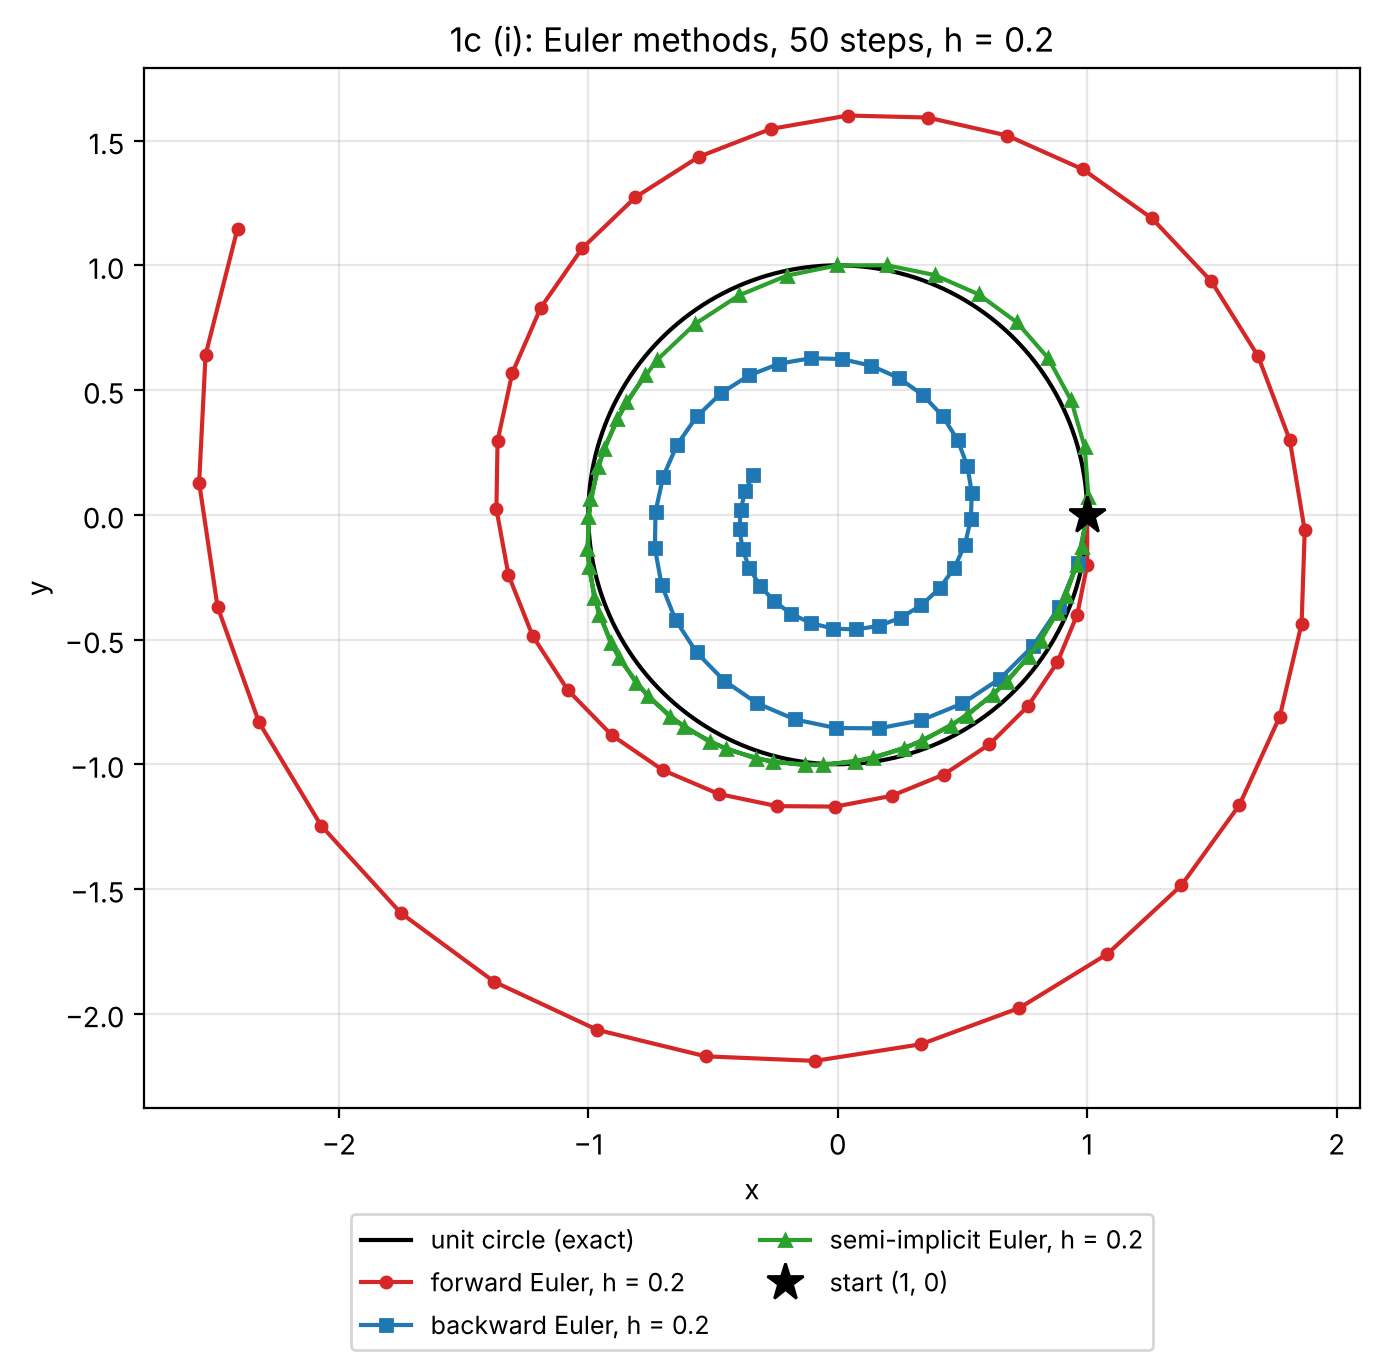

In [7]:
# ---------------- plot 1c (i): the three Euler methods ----------------
fig, ax = plt.subplots(figsize=(7, 7.8))
ax.plot(cx, cy, "k-", lw=1.5, label="unit circle (exact)")
ax.plot(x_fe, y_fe, "o-", color="#d62728", ms=4, label="forward Euler, h = 0.2")
ax.plot(x_be, y_be, "s-", color="#1f77b4", ms=4, label="backward Euler, h = 0.2")
ax.plot(x_si, y_si, "^-", color="#2ca02c", ms=4, label="semi-implicit Euler, h = 0.2")
ax.plot(x0, y0, "k*", ms=14, label="start (1, 0)")
ax.set_aspect("equal")             # a circle must look like a circle
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("1c (i): Euler methods, 50 steps, h = 0.2")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("ps7_ex1c_i.png", dpi=150)
plt.show()

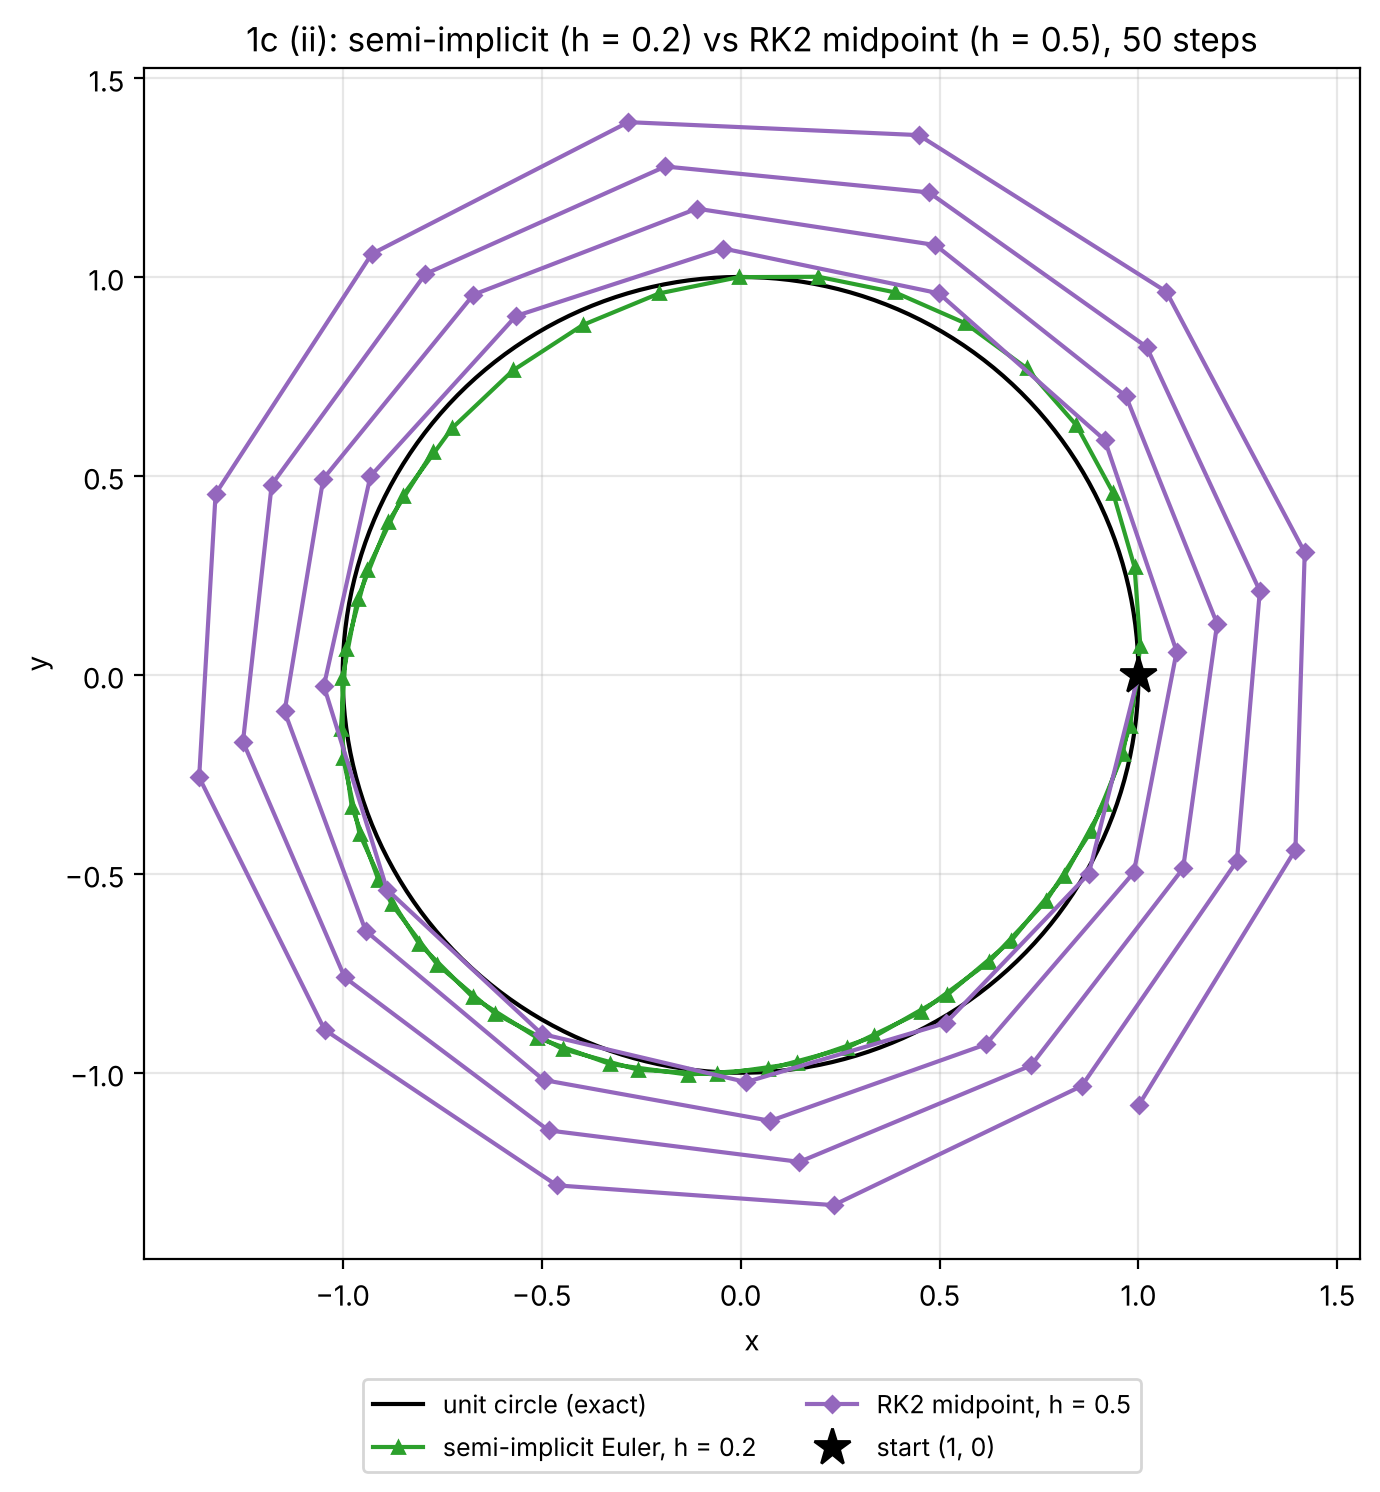

In [8]:
# ---------------- plot 1c (ii): semi-implicit h=0.2 vs RK2 h=0.5 ----------------
fig, ax = plt.subplots(figsize=(7, 7.8))
ax.plot(cx, cy, "k-", lw=1.5, label="unit circle (exact)")
ax.plot(x_si, y_si, "^-", color="#2ca02c", ms=4, label="semi-implicit Euler, h = 0.2")
ax.plot(x_rk5, y_rk5, "D-", color="#9467bd", ms=4, label="RK2 midpoint, h = 0.5")
ax.plot(x0, y0, "k*", ms=14, label="start (1, 0)")
ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("1c (ii): semi-implicit (h = 0.2) vs RK2 midpoint (h = 0.5), 50 steps")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("ps7_ex1c_ii.png", dpi=150)
plt.show()

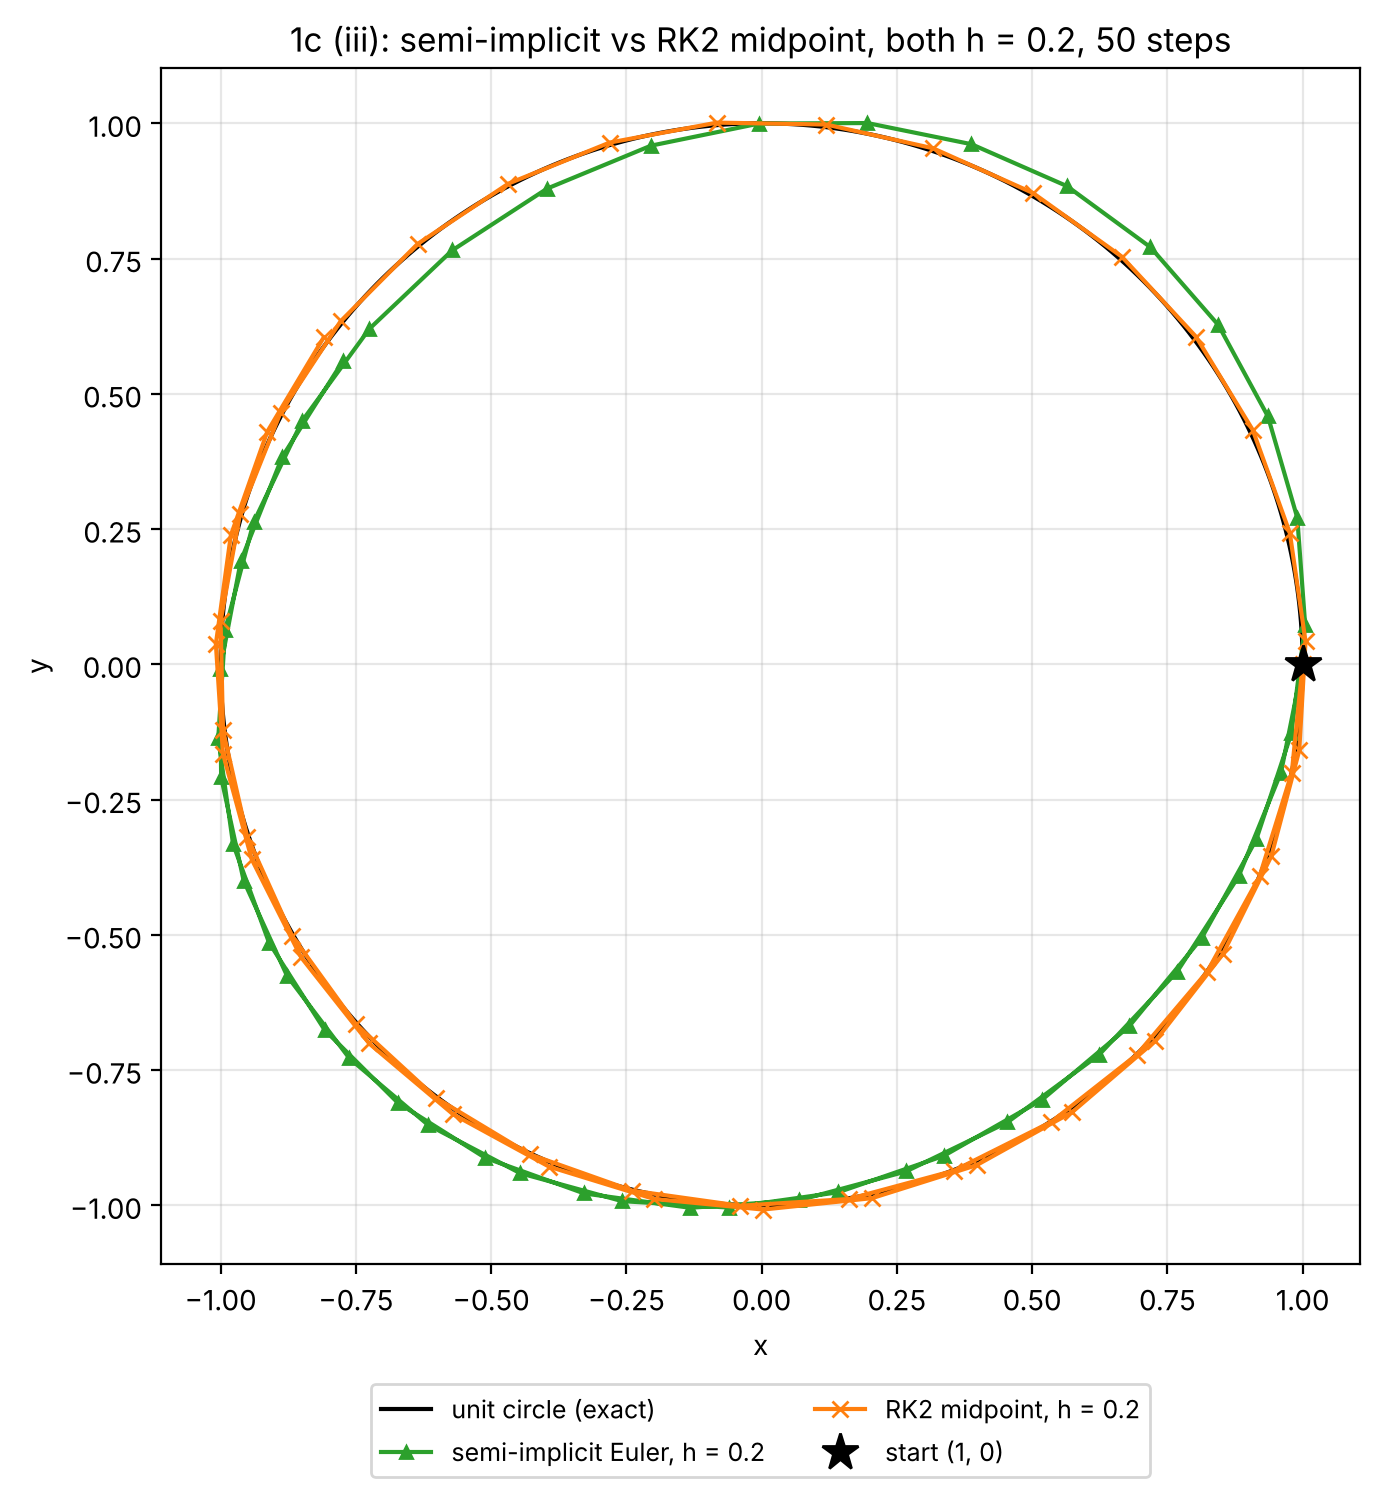

In [9]:
# ---------------- plot 1c (iii): semi-implicit h=0.2 vs RK2 h=0.2 ----------------
fig, ax = plt.subplots(figsize=(7, 7.8))
ax.plot(cx, cy, "k-", lw=1.5, label="unit circle (exact)")
ax.plot(x_si, y_si, "^-", color="#2ca02c", ms=4, label="semi-implicit Euler, h = 0.2")
ax.plot(x_rk, y_rk, "x-", color="#ff7f0e", ms=6, label="RK2 midpoint, h = 0.2")
ax.plot(x0, y0, "k*", ms=14, label="start (1, 0)")
ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("1c (iii): semi-implicit vs RK2 midpoint, both h = 0.2, 50 steps")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("ps7_ex1c_iii.png", dpi=150)
plt.show()

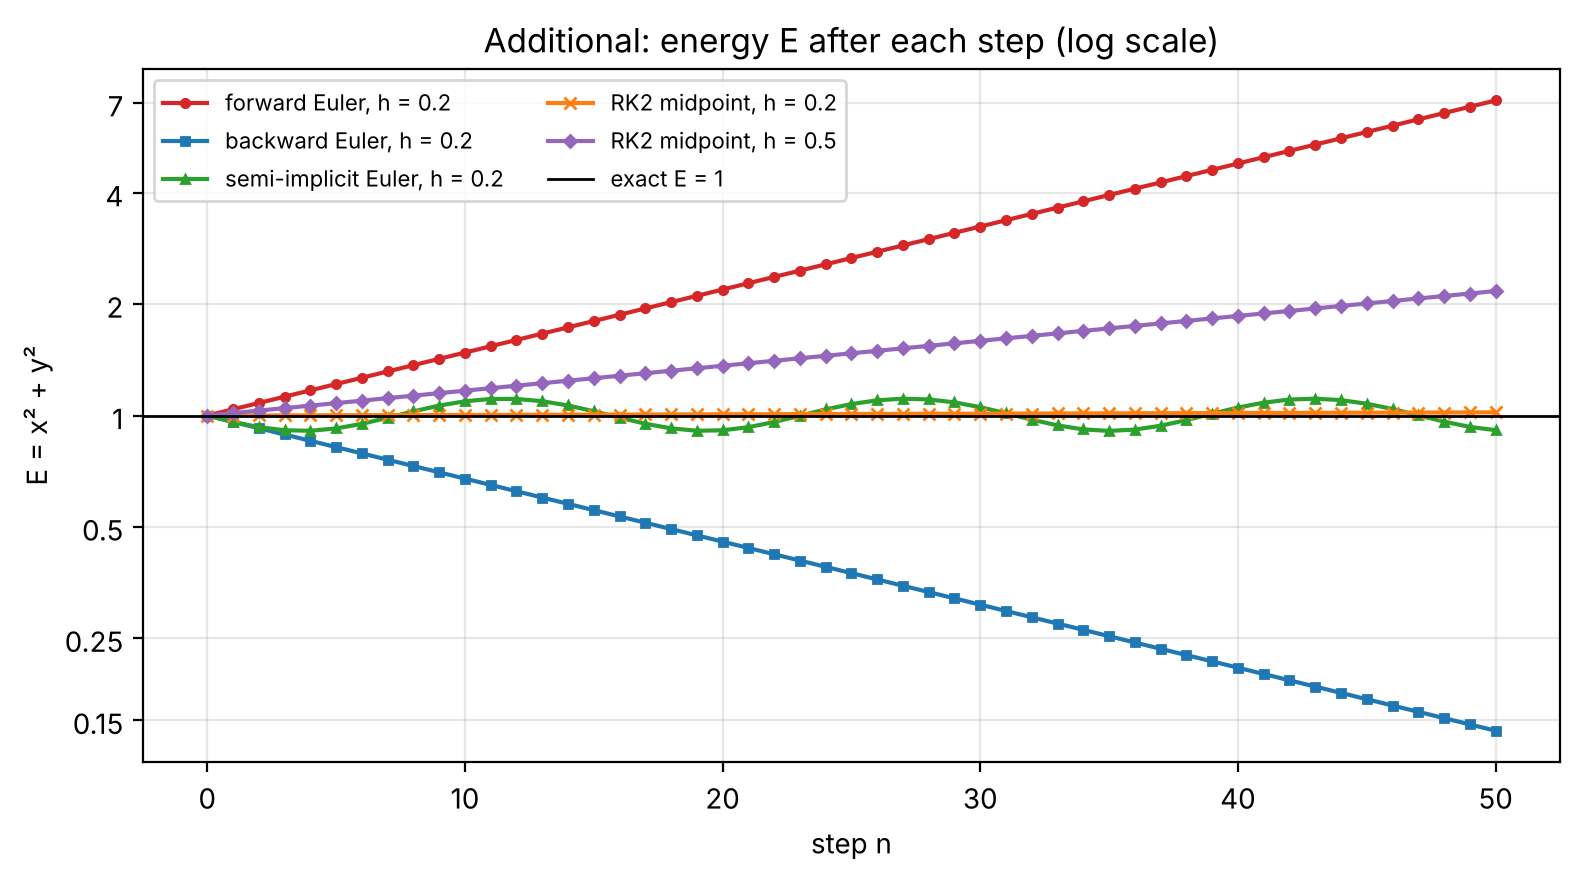

In [10]:
# ---------------- additional figure for 1(d): E over the step number ----------------
fig, ax = plt.subplots(figsize=(8, 4.5))
n_steps = np.arange(N + 1)
ax.plot(n_steps, E_fe, "o-", color="#d62728", ms=3, label="forward Euler, h = 0.2")
ax.plot(n_steps, E_be, "s-", color="#1f77b4", ms=3, label="backward Euler, h = 0.2")
ax.plot(n_steps, E_si, "^-", color="#2ca02c", ms=3, label="semi-implicit Euler, h = 0.2")
ax.plot(n_steps, E_rk, "x-", color="#ff7f0e", ms=4, label="RK2 midpoint, h = 0.2")
ax.plot(n_steps, E_rk5, "D-", color="#9467bd", ms=3, label="RK2 midpoint, h = 0.5")
ax.axhline(1.0, color="k", lw=1, label="exact E = 1")
ax.set_yscale("log")
ticks = [0.15, 0.25, 0.5, 1, 2, 4, 7]
ax.set_yticks(ticks); ax.set_yticklabels([str(v) for v in ticks]); ax.minorticks_off()
ax.set_xlabel("step n"); ax.set_ylabel("E = x² + y²")
ax.set_title("Additional: energy E after each step (log scale)")
ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("ps7_ex1d_energy.png", dpi=150)
plt.show()